# Scenario 3 — Customer Segmentation Query
**Lab:** Generative AI for Data Science · **Focus:** SQL prompting, date filters, top-spender selection, CTEs, query optimization and reproducible testing

**Given schema:**
- `user_activity(user_id, last_login_date, feature_usage_count, account_type)`
- `transactions(transaction_id, user_id, transaction_date, amount, platform)`
- `user_preferences(user_id, communication_preference, interface_theme, notification_settings)`

**Business question:** Identify users who logged in during the last 30 calendar dates, select the top **20% of active users by spending**, and summarize their stated preferences for a new feature rollout.

**Assumptions:** For a time-relevant launch, spending is summed over the *same 30-day window*; all `amount` values are nonnegative completed sales; `user_activity` and `user_preferences` have one row per user. We explicitly state these assumptions because the screenshot did not define the spending horizon or transaction status. Illustrative data are generated in-memory.

## 1. Your Prompt — first iteration

> **Role:** Act as a senior product analytics engineer and SQL developer. Using the exact tables and columns above, write SQL to identify users active during the last 30 days, rank customers by total purchase amount, select the highest-spending 20% of those active users, and report their communication, interface and notification preferences. Explain how the date window and percentile selection work. Use CTEs for readability and propose a visualization-friendly output.

**Why this prompt:** It supplies the database schema, explicit business question, intended ranking cohort, and expected output fields. A useful SQL prompt must define both the *unit being ranked* (customer) and the *population* used to calculate percentile thresholds.

## 2. Generated Code — initial SQL draft (retained for comparison)

```sql
SELECT a.user_id, SUM(t.amount) AS total_spend,
       p.communication_preference, p.interface_theme
FROM user_activity a
JOIN transactions t ON a.user_id = t.user_id
JOIN user_preferences p ON p.user_id = a.user_id
WHERE a.last_login_date >= CURRENT_DATE - INTERVAL '30 days'
GROUP BY a.user_id, p.communication_preference, p.interface_theme
ORDER BY total_spend DESC;
```

**Review:** The draft does not implement **top 20%**, is tied to a particular SQL dialect, lacks an upper date boundary, does not filter transaction dates, and can duplicate spending if preferences contain multiple rows per user. Inner joins also silently drop active users with no transactions or preferences. We refine it before use.

## 3. Follow-up Prompts — optimization and explanation

**Follow-up A:** “Rewrite for SQLite so it can run in a standalone notebook using `sqlite3`. Parameterize an `as_of_date`; use ISO-8601 date strings and **exactly 30 calendar dates including the as-of date**. First filter active users, then aggregate their completed transaction amounts for the same window, and only then rank users. Select `ceil(0.20 × active_user_count)` using a deterministic tie-break on `user_id`. Keep preference-free customers by a `LEFT JOIN`.”

**Follow-up B:** “Explain the CTEs, correct the risks of duplicate transaction counting, include a separate query for preference distributions, and add performance-oriented indexes. Keep filters sargable (avoid applying functions to indexed date columns) and test against synthetic data with one inactive big spender and an out-of-window transaction.”

**Improvement rationale:** The second iteration makes the cohort, percentile method, as-of boundaries, missing preferences, join grain, indexing, and validation explicit. It replaces ambiguous syntax with a runnable example while preserving the business requirements.

## 4. Final Solution — build a tiny SQLite test database

No database connection or real customer records were supplied. This notebook uses `sqlite3` and clearly labeled synthetic data. Replace the demo connection with your production database only after adjusting date syntax and indexing for that SQL dialect.

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

AS_OF_DATE = '2026-11-25'  # fixed for reproducible demonstrations
con = sqlite3.connect(':memory:')
con.executescript("""
CREATE TABLE user_activity (
    user_id INTEGER PRIMARY KEY,
    last_login_date TEXT NOT NULL,
    feature_usage_count INTEGER NOT NULL,
    account_type TEXT NOT NULL
);
CREATE TABLE transactions (
    transaction_id INTEGER PRIMARY KEY,
    user_id INTEGER NOT NULL,
    transaction_date TEXT NOT NULL,
    amount REAL NOT NULL,
    platform TEXT NOT NULL
);
CREATE TABLE user_preferences (
    user_id INTEGER PRIMARY KEY,
    communication_preference TEXT,
    interface_theme TEXT,
    notification_settings TEXT
);
CREATE INDEX ix_user_login ON user_activity(last_login_date);
CREATE INDEX ix_txn_user_date ON transactions(user_id, transaction_date);
""")

activity = [
 (1,'2026-11-25',21,'premium'), (2,'2026-11-23',18,'free'),
 (3,'2026-11-19',14,'premium'), (4,'2026-11-21',4,'free'),
 (5,'2026-11-22',8,'free'), (6,'2026-11-18',2,'free'),
 (7,'2026-11-24',11,'premium'), (8,'2026-11-02',6,'free'),
 (9,'2026-11-12',5,'free'), (10,'2026-11-25',8,'free'),
 (11,'2026-11-04',3,'free'),
 (12,'2026-08-20',50,'premium'),  # deliberately inactive large spender
]
transactions = [
 (100,1,'2026-11-20',900,'web'),(101,1,'2026-11-23',700,'app'),
 (102,2,'2026-11-18',500,'web'),(103,2,'2026-11-22',300,'app'),
 (104,3,'2026-11-20',1000,'app'),
 (105,4,'2026-11-23',100,'web'),(106,4,'2026-11-24',200,'app'),
 (107,5,'2026-11-22',50,'web'),
 (108,7,'2026-11-20',750,'app'),(109,8,'2026-11-12',230,'web'),
 (110,9,'2026-11-11',120,'app'),(111,10,'2026-11-10',60,'web'),
 (112,11,'2026-11-04',30,'app'),
 (113,12,'2026-11-22',2400,'web'),  # exclude inactive user
 (114,2,'2026-10-01',3000,'app'),  # exclude old spending
 (115,7,'2026-12-01',10000,'app'), # exclude future spending
]
prefs = [
 (1,'email','dark','on'),(2,'sms','light','off'),
 # user 3 has no row: exercise LEFT JOIN and Unspecified
 (4,'email','light','on'),(5,'push','dark','on'),
 (6,'sms','light','off'),(7,'push','dark','on'),
 (8,'email','light','off'),(9,'push','light','on'),
 (10,'sms','light','on'),(11,'email','dark','on'),
 (12,'email','dark','on'),
]
con.executemany('INSERT INTO user_activity VALUES (?,?,?,?)', activity)
con.executemany('INSERT INTO transactions VALUES (?,?,?,?,?)', transactions)
con.executemany('INSERT INTO user_preferences VALUES (?,?,?,?)', prefs)
con.commit()
print('Synthetic SQLite demo database loaded')

Synthetic SQLite demo database loaded


### CTE logic (read before executing)

1. `active_users`: users with `last_login_date` in the inclusive 30-calendar-date window ending on `:as_of_date`.
2. `spend_30d`: one row per user after aggregating qualifying purchase rows. This prevents duplicate spending from downstream joins.
3. `ranked`: left-join spend to the active cohort; deterministic `ROW_NUMBER` rank by spend descending then ID ascending; count active users with a window function.
4. `high_value`: top `ceil(20% × number_of_active_users)`; require positive spend to avoid labeling non-spenders as high-value.
5. Final result: left-join preferences, treating missing values as `Unspecified`. The top 20% rule is based on **customer count**, not the share of total revenue. Ties at the boundary are broken by customer ID; some businesses instead include all boundary ties.

In [2]:
cte_sql = """
WITH active_users AS (
    SELECT user_id, account_type, feature_usage_count, last_login_date
    FROM user_activity
    WHERE last_login_date >= date(:as_of_date, '-29 days')
      AND last_login_date < date(:as_of_date, '+1 day')
),
spend_30d AS (
    SELECT t.user_id, SUM(t.amount) AS spend_30d,
           COUNT(DISTINCT t.transaction_id) AS transactions_30d
    FROM transactions AS t
    INNER JOIN active_users AS a ON a.user_id = t.user_id
    WHERE t.transaction_date >= date(:as_of_date, '-29 days')
      AND t.transaction_date < date(:as_of_date, '+1 day')
    GROUP BY t.user_id
),
ranked AS (
    SELECT a.user_id, a.account_type, a.feature_usage_count,
           a.last_login_date,
           COALESCE(s.spend_30d, 0) AS spend_30d,
           COALESCE(s.transactions_30d, 0) AS transactions_30d,
           ROW_NUMBER() OVER (
               ORDER BY COALESCE(s.spend_30d, 0) DESC, a.user_id ASC
           ) AS spend_rank,
           COUNT(*) OVER () AS active_user_count
    FROM active_users AS a
    LEFT JOIN spend_30d AS s ON s.user_id = a.user_id
),
high_value AS (
    SELECT * FROM ranked
    WHERE spend_rank <= CAST((active_user_count + 4) / 5 AS INTEGER)
      AND spend_30d > 0
)
"""

sql_customers = cte_sql + """
SELECT h.user_id, h.account_type, h.feature_usage_count,
       h.last_login_date, h.spend_30d, h.transactions_30d,
       h.spend_rank, h.active_user_count,
       COALESCE(p.communication_preference, 'Unspecified') AS communication_preference,
       COALESCE(p.interface_theme, 'Unspecified') AS interface_theme,
       COALESCE(p.notification_settings, 'Unspecified') AS notification_settings
FROM high_value AS h
LEFT JOIN user_preferences AS p ON p.user_id = h.user_id
ORDER BY h.spend_rank, h.user_id
"""

sql_preferences = cte_sql + """
SELECT COALESCE(p.communication_preference, 'Unspecified') AS communication_preference,
       COALESCE(p.interface_theme, 'Unspecified') AS interface_theme,
       COALESCE(p.notification_settings, 'Unspecified') AS notification_settings,
       COUNT(*) AS high_value_customers,
       ROUND(AVG(h.spend_30d), 2) AS avg_customer_spend_30d
FROM high_value AS h
LEFT JOIN user_preferences AS p ON p.user_id = h.user_id
GROUP BY COALESCE(p.communication_preference, 'Unspecified'),
         COALESCE(p.interface_theme, 'Unspecified'),
         COALESCE(p.notification_settings, 'Unspecified')
ORDER BY high_value_customers DESC, communication_preference
"""

customers = pd.read_sql_query(sql_customers, con, params={'as_of_date':AS_OF_DATE})
preference_trends = pd.read_sql_query(sql_preferences, con, params={'as_of_date':AS_OF_DATE})
print('Top spending active customers:')
print(customers.to_string(index=False))
print('\nPreference trends:')
print(preference_trends.to_string(index=False))

Top spending active customers:
 user_id account_type  feature_usage_count last_login_date  spend_30d  transactions_30d  spend_rank  active_user_count communication_preference interface_theme notification_settings
       1      premium                   21      2026-11-25     1600.0                 2           1                 11                    email            dark                    on
       3      premium                   14      2026-11-19     1000.0                 1           2                 11              Unspecified     Unspecified           Unspecified
       2         free                   18      2026-11-23      800.0                 2           3                 11                      sms           light                   off

Preference trends:
communication_preference interface_theme notification_settings  high_value_customers  avg_customer_spend_30d
             Unspecified     Unspecified           Unspecified                     1                  1000.0
   

In [3]:
# Validate cohort, 30-day window, IDs, non-duplication, and rank logic.
assert list(customers['user_id']) == [1,3,2], customers['user_id'].tolist()
assert customers['user_id'].is_unique
assert len(customers) == 3   # ceil(0.2 * 11 active users) = 3
assert customers.loc[customers['user_id'].eq(2),'spend_30d'].item() == 800.0
assert 12 not in customers['user_id'].tolist()  # inactive large spender excluded
assert 7 not in customers['user_id'].tolist()   # future transaction excluded
assert customers.loc[customers['user_id'].eq(3),'communication_preference'].item() == 'Unspecified'
assert preference_trends['high_value_customers'].sum() == len(customers)
print('SQL cohort and metric tests passed')

print('\nIndexed access / query plan (SQLite):')
for row in con.execute('EXPLAIN QUERY PLAN ' + sql_customers,
                       {'as_of_date':AS_OF_DATE}).fetchall()[-10:]:
    print(row[3])

SQL cohort and metric tests passed

Indexed access / query plan (SQLite):
USE TEMP B-TREE FOR count(DISTINCT)
SEARCH user_activity USING INDEX ix_user_login (last_login_date>? AND last_login_date<?)
BLOOM FILTER ON s (user_id=?)
SEARCH s USING AUTOMATIC COVERING INDEX (user_id=?) LEFT-JOIN
SCAN (subquery-7)
USE TEMP B-TREE FOR ORDER BY
SCAN (subquery-6)
SCAN ranked
SEARCH p USING INTEGER PRIMARY KEY (rowid=?) LEFT-JOIN
USE TEMP B-TREE FOR ORDER BY


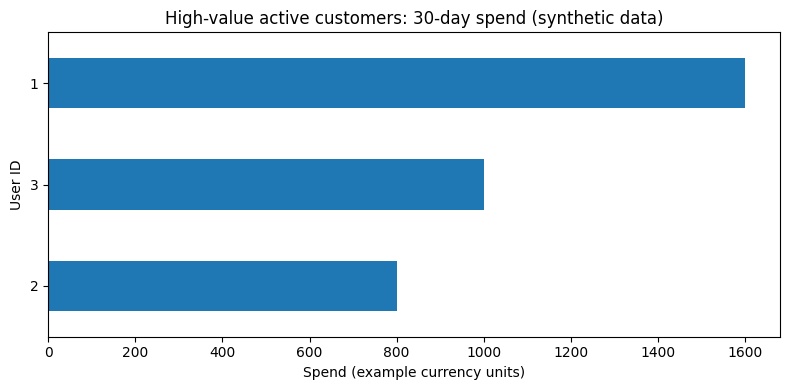

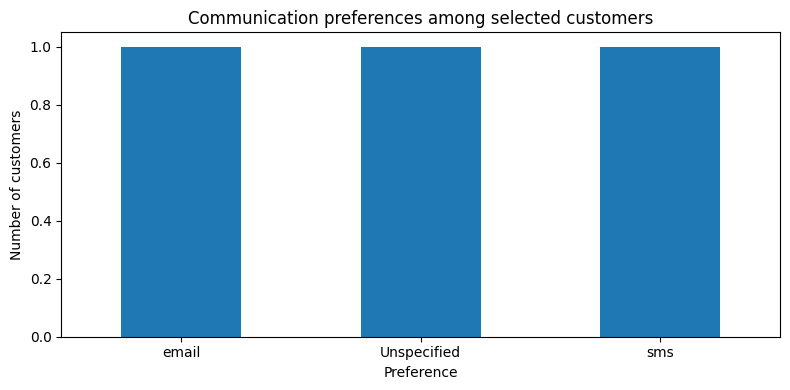

In [4]:
# Visualization-friendly trend summaries for selected top spenders.
if not customers.empty:
    ax = customers.sort_values('spend_30d').plot.barh(
        x='user_id', y='spend_30d', legend=False, figsize=(8,4))
    ax.set_title('High-value active customers: 30-day spend (synthetic data)')
    ax.set_xlabel('Spend (example currency units)')
    ax.set_ylabel('User ID')
    plt.tight_layout(); plt.show()

    pref_counts = customers['communication_preference'].value_counts()
    ax = pref_counts.plot.bar(figsize=(8,4))
    ax.set_title('Communication preferences among selected customers')
    ax.set_xlabel('Preference')
    ax.set_ylabel('Number of customers')
    plt.xticks(rotation=0)
    plt.tight_layout(); plt.show()

## 5. Results and Discussion

**1. How were percentile calculations handled?** The initial query sorted customers by spending but did not actually select the top 20%. The refined query first defines the active-user cohort, then ranks its members by **30-day total spending** using `ROW_NUMBER() OVER (ORDER BY spend_30d DESC, user_id ASC)`. It selects the first `ceil(0.2 × active_user_count)` customers. Using a row-count threshold rather than a revenue threshold ensures that approximately 20% of eligible customers are selected. The deterministic secondary sort avoids unstable results when spending ties occur.

**2. What approaches to date filtering were used?** The first draft used database-dependent `CURRENT_DATE - INTERVAL '30 days'` and did not filter transaction dates. The refined SQLite query accepts a bound `as_of_date` parameter and selects the last **30 calendar dates, including that date**, with lower-inclusive/upper-exclusive boundaries. It applies the same window to logins and purchases, preventing historical or future transactions from distorting the target group. A fixed as-of date makes the example reproducible.

**3. How was the query optimized using CTEs/subqueries?** The final query uses descriptive CTEs for active users, per-user transaction totals, ranking, and high-value selection. Transaction amounts are aggregated **before** joining preferences, preventing duplicate totals. It uses `LEFT JOIN` to retain active customers without purchases or preference records, filters early, applies parameterized boundaries, avoids wrapping indexed date columns in functions, and creates indexes for the main filters and joins. The notebook also shows the SQLite query plan and verifies results on known edge cases.

**Peer discussion prompt:** If two customers tie for the exact 20th-percentile cutoff, should we keep a strict headcount or include all tied spenders? How could that decision affect experimental rollout size and fairness?

**Reflection:** The refinement transformed an incomplete list of spenders into a clearly defined cohort with stable ranking, reproducible date logic, query performance considerations, and visualization-ready preference summaries.

### Deployment cautions

This notebook is for a **local SQLite illustration**. PostgreSQL, BigQuery, Snowflake, and Spark SQL use different interval/date syntax and query-plan conventions. Real production segmentation should also define refund handling, transaction status, currency normalization, user consent, user record uniqueness, and whether “high-value” refers to lifetime or last-30-day spending. The screenshots specify no such rules; this lab states its chosen assumptions instead of inventing them.